# Advanced Machine Learning (CS60073)
## **Assignment 3:** Generative modeling (Total Marks: 100)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

RANDOM_SEED = 1234
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
device = torch.device("cpu")

## Part-A: VAE & GAN (Total: 60 marks)

**Goal:** Compare explicit-likelihood (VAE) and adversarial (GAN) generative modeling on `MNIST (28×28 grayscale)`.

**Settings**
- Splits: Train 50,000 / Val 10,000 / Test 10,000 (from `torchvision MNIST`: split the 60k train into 50k/10k).
- Inputs normalized to [0, 1]; for MLPs, flatten to 784.
- Optimizer: `Adam`, weight decay 0, batch size 128, epochs 10.
- Report losses per epoch and save fixed 10×10 sample grids each epoch.

### 0.1) Dataset loading and splitting

This cell downloads MNIST, converts images to tensors in the range \($[0,1]$\), and creates the required train/validation/test splits. A fixed generator seed ensures that the 50,000/10,000 split is reproducible. DataLoaders use a batch size of 128.

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Define image transformation (normalization)
transform = transforms.ToTensor()

# Load MNIST training and test datasets
train_val_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Split the original 60,000 training images into 50,000 training and 10,000 validation images
train_dataset, val_dataset = random_split(
    train_val_dataset, [50000, 10000], generator=torch.Generator().manual_seed(RANDOM_SEED)
)

# Define DataLoaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)

# Print dataset sizes
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Training samples: 50000
Validation samples: 10000
Test samples: 10000


### 0.2) Input shape verification

This cell verifies the shape and value range of a batch of MNIST images. The images are flattened into 784-dimensional vectors for MLP-based generative models.

In [3]:
# Get one batch of training images
images, labels = next(iter(train_loader))

# Flatten images for MLPs
images_flat = images.view(images.size(0), -1)

# Print batch information
print(f"Batch shape: {images.shape}")
print(f"Single image shape: {images[0].shape}")
print(f"Flattened batch shape: {images_flat.shape}")
print(f"Minimum pixel value: {images_flat.min().item():.4f}")
print(f"Maximum pixel value: {images_flat.max().item():.4f}")

Batch shape: torch.Size([128, 1, 28, 28])
Single image shape: torch.Size([1, 28, 28])
Flattened batch shape: torch.Size([128, 784])
Minimum pixel value: 0.0000
Maximum pixel value: 1.0000


## 1) Variational Autoencoder (10 marks)

**Architecture (MLP)**
- **Encoder (input 784):** Linear(784→512) + ReLU; Linear(512→256) + ReLU; heads μ: Linear(256→16), log σ2: Linear(256→16).
- **Latent:** $z = \mu + \sigma \odot \epsilon, \quad \epsilon \sim \mathcal{N}(0, I_{16}).$
- **Decoder (input 16):** Linear(16→256) + ReLU; Linear(256→512) + ReLU; Linear(512→784) + Sigmoid.
- **Loss:** Reconstruction (binary cross-entropy, summed over pixels, averaged over batch) + KL to $\mathcal{N}(0, I)$.
- **Training:** Adam(lr=1e-3, betas=(0.9,0.999)), epochs=10, batch=128.
- **Output:** Plot reconstruction, KL, and total ELBO per epoch.

### 1.1) VAE Architecture

The encoder transforms each 784-dimensional input image through hidden layers of 512 and 256 units, producing a 16-dimensional latent mean \($\mu$\) and log-variance \($\log\sigma^2$\). The reparameterization trick is employed to enable gradient-based optimization through stochastic latent sampling. The decoder maps the 16-dimensional latent vector through hidden layers of 256 and 512 units to reconstruct the input image, with a sigmoid output layer that constrains pixel values to the range \($[0,1]$\).

In [4]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(256, 16)
        self.fc_log_var = nn.Linear(256, 16)
        self.decoder = nn.Sequential(
            nn.Linear(16, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        sigma = torch.exp(0.5 * log_var)
        epsilon = torch.randn_like(sigma)
        return mu + sigma * epsilon

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        reconstruction = self.decode(z)
        return reconstruction, mu, log_var

vae = VAE().to(device)
optimizer_vae = optim.Adam(vae.parameters(), lr=1e-3, betas=(0.9, 0.999), weight_decay=0)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_log_var): Linear(in_features=256, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### 1.2) Reconstruction, KL, and Total Losses

- The reconstruction loss is computed using binary cross-entropy, summed over the 784 pixels of each image and averaged over the batch. 
$$
\mathcal{L}_{\mathrm{recon}}
=-\frac{1}{B}\sum_{i=1}^{B}\sum_{j=1}^{784}
\left[
x_{ij}\log\hat{x}_{ij}
+(1-x_{ij})\log(1-\hat{x}_{ij})
\right]
$$

- The KL divergence between the diagonal Gaussian approximate posterior and the standard normal prior is computed analytically. 
$$
\mathcal{L}_{\mathrm{KL}}
=-\frac{1}{2B}\sum_{i=1}^{B}\sum_{j=1}^{16}
\left[
1+\log\sigma_{ij}^{2}
-\mu_{ij}^{2}
-\sigma_{ij}^{2}
\right]
$$

- The total loss is obtained by summing the reconstruction loss and KL divergence, corresponding to the negative evidence lower bound (negative ELBO), which is minimized during training.
$$
\mathcal{L}_{\mathrm{total}}
=\mathcal{L}_{\mathrm{recon}}+\mathcal{L}_{\mathrm{KL}}
$$

In [5]:
def vae_loss(reconstruction, x, mu, log_var):
    batch_size = x.size(0)
    recon_loss = F.binary_cross_entropy(reconstruction, x, reduction="sum") / batch_size
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / batch_size
    total_loss = recon_loss + kl_loss
    return recon_loss, kl_loss, total_loss

### 1.3) Fixed 10x10 sample grid per Epoch

A set of 100 latent vectors is sampled once from the standard normal prior and reused after each epoch to monitor the evolution of generated images during training. The vectors are decoded using the current decoder, and the resulting grayscale images are saved as a \($10\times10$\) grid. Using fixed latent vectors enables consistent visual comparisons across epochs.

In [6]:
# Generate fixed latent vectors for sample grids
sample_generator = torch.Generator(device="cpu").manual_seed(RANDOM_SEED)
fixed_z_vae = torch.randn(100, 16, generator=sample_generator).to(device)

# Create directory for generated samples
os.makedirs("vae_samples", exist_ok=True)

print(f"Fixed latent vectors shape: {fixed_z_vae.shape}")

Fixed latent vectors shape: torch.Size([100, 16])


### 1.4) VAE Training and Evaluation

The VAE is trained for exactly 10 epochs using `Adam` with a learning rate of \($10^{-3}$\), betas \($(0.9,0.999)$\), and a batch size of 128. At the end of each epoch, the model is evaluated on the validation set without updating its parameters. The losses are accumulated with batch-size weighting to ensure that the epoch averages correctly account for the smaller final batch.

In [7]:
epochs_vae = 10

history_vae = {
    "train_recon": [],
    "train_kl": [],
    "train_total": [],
    "val_recon": [],
    "val_kl": [],
    "val_total": []
}

for epoch in range(epochs_vae):
    vae.train()
    train_sums = np.zeros(3)
    train_count = 0

    for images, _ in train_loader:
        x = images.view(images.size(0), -1).to(device)
        optimizer_vae.zero_grad()

        reconstruction, mu, log_var = vae(x)
        recon_loss, kl_loss, total_loss = vae_loss(reconstruction, x, mu, log_var)

        total_loss.backward()
        optimizer_vae.step()

        batch_size_actual = x.size(0)
        train_sums += np.array([
            recon_loss.item(),
            kl_loss.item(),
            total_loss.item()
        ]) * batch_size_actual
        train_count += batch_size_actual

    vae.eval()
    val_sums = np.zeros(3)
    val_count = 0

    with torch.no_grad():
        for images, _ in val_loader:
            x = images.view(images.size(0), -1).to(device)

            reconstruction, mu, log_var = vae(x)
            recon_loss, kl_loss, total_loss = vae_loss(reconstruction, x, mu, log_var)

            batch_size_actual = x.size(0)
            val_sums += np.array([
                recon_loss.item(),
                kl_loss.item(),
                total_loss.item()
            ]) * batch_size_actual
            val_count += batch_size_actual

    train_avg = train_sums / train_count
    val_avg = val_sums / val_count

    for key, value in zip(["train_recon", "train_kl", "train_total"], train_avg):
        history_vae[key].append(value)

    for key, value in zip(["val_recon", "val_kl", "val_total"], val_avg):
        history_vae[key].append(value)

    print(
        f"Epoch [{epoch + 1:02d}/{epochs_vae}] | "
        f"Train: Recon={train_avg[0]:.4f}, "
        f"KL={train_avg[1]:.4f}, Total={train_avg[2]:.4f} | "
        f"Val: Recon={val_avg[0]:.4f}, "
        f"KL={val_avg[1]:.4f}, Total={val_avg[2]:.4f}"
    )
    
    # Generate and save a 10x10 sample grid
    vae.eval()
    
    with torch.no_grad():
        generated = vae.decode(fixed_z_vae).view(100, 28, 28)

    fig, axes = plt.subplots(10, 10, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        ax.imshow(generated[i].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

    plt.tight_layout(pad=0.1)
    plt.savefig(f"vae_samples/epoch_{epoch + 1:02d}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved sample grid for epoch {epoch + 1}")

Epoch [01/10] | Train: Recon=172.3340, KL=7.4750, Total=179.8090 | Val: Recon=128.6825, KL=12.9067, Total=141.5893
Saved sample grid for epoch 1
Epoch [02/10] | Train: Recon=115.4008, KL=14.4841, Total=129.8849 | Val: Recon=108.4257, KL=15.3250, Total=123.7507
Saved sample grid for epoch 2
Epoch [03/10] | Train: Recon=102.8308, KL=16.2265, Total=119.0573 | Val: Recon=99.8658, KL=16.4033, Total=116.2691
Saved sample grid for epoch 3
Epoch [04/10] | Train: Recon=96.0130, KL=17.4805, Total=113.4935 | Val: Recon=94.9495, KL=17.5812, Total=112.5307
Saved sample grid for epoch 4
Epoch [05/10] | Train: Recon=92.1093, KL=18.1970, Total=110.3063 | Val: Recon=91.5011, KL=18.6038, Total=110.1049
Saved sample grid for epoch 5
Epoch [06/10] | Train: Recon=89.3973, KL=18.7276, Total=108.1249 | Val: Recon=89.9172, KL=18.5100, Total=108.4272
Saved sample grid for epoch 6
Epoch [07/10] | Train: Recon=87.4240, KL=19.0773, Total=106.5013 | Val: Recon=88.0194, KL=18.9714, Total=106.9908
Saved sample grid 

### 1.5) Losses per Epoch

The training and validation reconstruction losses, KL divergences, and total negative ELBO values are plotted against the epoch number. The total loss is expected to equal the sum of the reconstruction loss and KL divergence. Lower total loss values indicate a lower optimization objective, while the individual components provide additional insight into the model's learning behaviour.

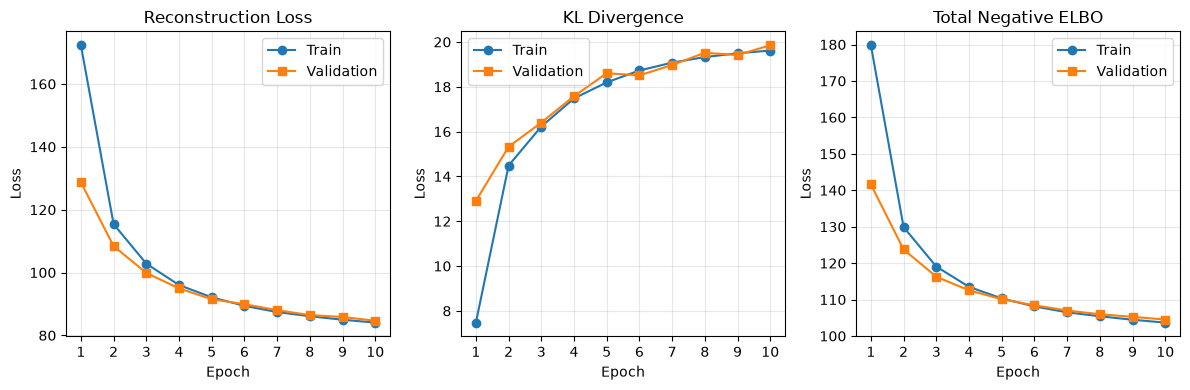

In [8]:
epoch_numbers = np.arange(1, epochs_vae + 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
loss_pairs = [("recon", "Reconstruction Loss"), ("kl", "KL Divergence"), ("total", "Total Negative ELBO")]

for ax, (key, title) in zip(axes, loss_pairs):
    ax.plot(epoch_numbers, history_vae[f"train_{key}"], marker="o", label="Train")
    ax.plot(epoch_numbers, history_vae[f"val_{key}"], marker="s", label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(epoch_numbers)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()

## 2) VAE Reconstruction & Generation (10 marks)
Show 5 validation images with reconstructions, side-by-side.
Sample 10 images by $z ∼ \mathcal{N}(0, I_{16})$ and decode; show a 2×5 grid.
Add a brief comment on sharpness/diversity.

### 2.1) Validation Images and their Reconstructions

Five images are selected from the validation set and passed through the trained VAE to obtain their reconstructions. The original and reconstructed images are displayed side by side for visual comparison. The posterior mean \($\mu$\) is used as the latent representation to ensure deterministic reconstruction without the variability introduced by random latent sampling.

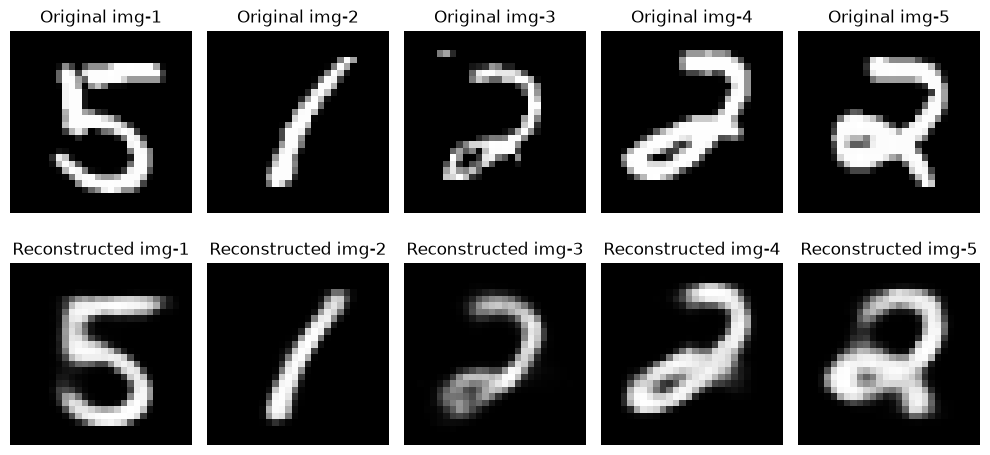

In [9]:
# Select five validation images
vae.eval()
images, _ = next(iter(val_loader))
x = images[:5].view(5, -1).to(device)

# Reconstruct using the latent mean
with torch.no_grad():
    mu, log_var = vae.encode(x)
    reconstruction = vae.decode(mu)

# Plot originals and reconstructions side by side
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i in range(5):
    axes[0, i].imshow(x[i].cpu().view(28, 28).numpy(), cmap="gray")
    axes[0, i].set_title(f"Original img-{i + 1}")
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstruction[i].cpu().view(28, 28).numpy(), cmap="gray")
    axes[1, i].set_title(f"Reconstructed img-{i + 1}")
    axes[1, i].axis("off")

plt.tight_layout()

### 2.2) Images from the Latent prior

Ten latent vectors are sampled from \($z\sim\mathcal{N}(0,I_{16})$\) and passed through the trained decoder to generate images. The resulting images are displayed in a \($2\times5$\) grid for visual inspection.

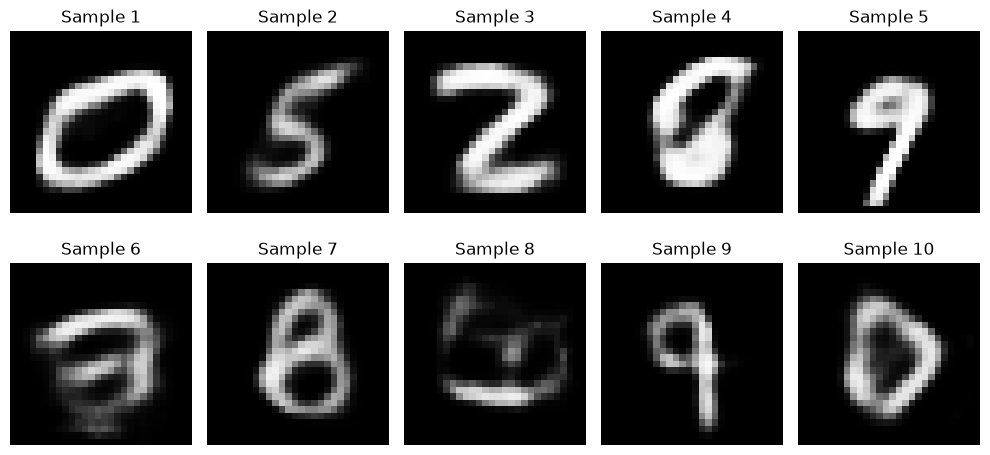

In [10]:
# Sample ten latent vectors from the standard normal prior
generation_generator = torch.Generator(device="cpu").manual_seed(RANDOM_SEED + 1)
z = torch.randn(10, 16, generator=generation_generator).to(device)

# Generate images using the trained decoder
vae.eval()
with torch.no_grad():
    generated_images = vae.decode(z).view(10, 28, 28)

# Plot generated images in a 2x5 grid
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Sample {i + 1}")
    ax.axis("off")

plt.tight_layout()

### 2.3) Comment on Sharpness/ Diversity

- **Reconstruction:** The reconstructed digits preserve the overall identity and structure of the original images, although some fine details are blurred.
- **Sharpness:** The VAE-generated digits are generally recognizable but appear somewhat blurry and lack fine details, because the model optimizes a probabilistic reconstruction objective.
- **Diversity:** Sampling different latent vectors produced varied digit shapes and styles, including several recognizable digits. The diversity and clarity of the generated samples reflect how well the VAE has learned a meaningful latent representation of the data.

## 3) GAN (MLP-based) – Training (10 marks)

- **Latent:** dz = 64.
- **Generator G** (use LeakyReLU(0.2) in hidden layers; last layer Tanh):
Linear(64→256) → LeakyReLU; Linear(256→512) → LeakyReLU; Linear(512→784) → Tanh.
- **Discriminator D** (use LeakyReLU(0.2); Dropout 0.3 after hidden layers; output is a logit):
Linear(784→512)→LeakyReLU→Dropout(0.3); Linear(512→256)→LeakyReLU→Dropout(0.3);
Linear(256→1).
- **Loss:** BCEWithLogitsLoss, non-saturating objective. Label smoothing: real=0.9, fake=0.0.
- **Optimization:** Adam(lr=2e-4, betas=(0.5,0.999)); batch=128; epochs=10; update D once
and G once per iteration.
- **Output:** Plot LD and LG per epoch.

### 3.1) Generator and Discriminator

The generator is designed to transform 64-dimensional latent noise vectors into flattened MNIST images of 784 pixels. The discriminator produces a single logit for each input image to distinguish real images from generated ones. A sigmoid activation is omitted from the discriminator output, as the sigmoid operation is handled internally by `BCEWithLogitsLoss`.

In [11]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(64, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.network(x)

generator = Generator().to(device)
discriminator = Discriminator().to(device)

# Define loss and optimizers
criterion_gan = nn.BCEWithLogitsLoss()
optimizer_g = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999), weight_decay=0)
optimizer_d = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999), weight_decay=0)

print(generator)
print(discriminator)

Generator(
  (network): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Tanh()
  )
)
Discriminator(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=1, bias=True)
  )
)


### 3.2) Fixed Latent Vectors

A set of 100 latent noise vectors is generated once and kept fixed throughout training. These vectors are reused after each epoch to monitor changes in the generator's outputs under consistent input conditions. A \($10\times10$\) grid of generated images is saved for each epoch to facilitate visual comparison.

In [12]:
# Generate fixed latent vectors for consistent sample grids
sample_generator_gan = torch.Generator(device="cpu").manual_seed(RANDOM_SEED)
fixed_z_gan = torch.randn(100, 64, generator=sample_generator_gan).to(device)

# Create directory for generated samples
os.makedirs("gan_samples", exist_ok=True)

print(f"Fixed GAN latent vectors shape: {fixed_z_gan.shape}")

Fixed GAN latent vectors shape: torch.Size([100, 64])


### 3.3) GAN Training

The GAN is trained for 10 epochs, with one discriminator update followed by one generator update for each batch. The discriminator is trained using real images with smoothed labels of 0.9 and generated images with labels of 0.0. The generator is optimized using a target label of 1.0 for its generated images, following the non-saturating objective. The discriminator loss is computed as the average of the losses for real and generated images.

In [13]:
epochs_gan = 10

history_gan = {
    "discriminator": [],
    "generator": []
}

for epoch in range(epochs_gan):
    generator.train()
    discriminator.train()

    epoch_d_loss = 0.0
    epoch_g_loss = 0.0
    sample_count = 0

    for images, _ in train_loader:
        batch_size_actual = images.size(0)

        # Prepare real images in the range [-1, 1]
        x_real = images.view(batch_size_actual, -1).to(device)
        x_real = 2 * x_real - 1

        # Create labels for real and fake images
        real_labels = torch.full((batch_size_actual, 1), 0.9, device=device)
        fake_labels = torch.zeros((batch_size_actual, 1), device=device)

        # -------------------------
        # Update discriminator
        # -------------------------
        optimizer_d.zero_grad()

        # Discriminator loss on real images
        real_logits = discriminator(x_real)
        loss_d_real = criterion_gan(real_logits, real_labels)

        # Generate fake images without updating the generator
        z = torch.randn(batch_size_actual, 64, device=device)
        fake_images = generator(z).detach()

        # Discriminator loss on fake images
        fake_logits = discriminator(fake_images)
        loss_d_fake = criterion_gan(fake_logits, fake_labels)

        # Average real and fake losses
        loss_d = 0.5 * (loss_d_real + loss_d_fake)
        loss_d.backward()
        optimizer_d.step()

        # -------------------------
        # Update generator
        # -------------------------
        optimizer_g.zero_grad()

        # Freeze discriminator parameters while updating generator
        for parameter in discriminator.parameters():
            parameter.requires_grad_(False)

        z = torch.randn(batch_size_actual, 64, device=device)
        generated_images = generator(z)
        generated_logits = discriminator(generated_images)

        # Generator aims to fool discriminator
        generator_labels = torch.ones((batch_size_actual, 1), device=device)
        loss_g = criterion_gan(generated_logits, generator_labels)

        loss_g.backward()
        optimizer_g.step()

        # Re-enable discriminator gradients for the next iteration
        for parameter in discriminator.parameters():
            parameter.requires_grad_(True)

        # Accumulate losses weighted by batch size
        epoch_d_loss += loss_d.item() * batch_size_actual
        epoch_g_loss += loss_g.item() * batch_size_actual
        sample_count += batch_size_actual

    # Calculate average losses for the epoch
    avg_d_loss = epoch_d_loss / sample_count
    avg_g_loss = epoch_g_loss / sample_count

    history_gan["discriminator"].append(avg_d_loss)
    history_gan["generator"].append(avg_g_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{epochs_gan}] | "
        f"Discriminator Loss={avg_d_loss:.4f} | "
        f"Generator Loss={avg_g_loss:.4f}"
    )

    # Generate and save a fixed 10x10 sample grid
    generator.eval()
    with torch.no_grad():
        generated = generator(fixed_z_gan).view(100, 28, 28)
        generated = (generated + 1) / 2  # Convert [-1, 1] to [0, 1]

    fig, axes = plt.subplots(10, 10, figsize=(10, 10))

    for i, ax in enumerate(axes.flat):
        ax.imshow(generated[i].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

    plt.tight_layout(pad=0.1)
    plt.savefig(f"gan_samples/epoch_{epoch + 1:02d}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    
    print(f"Saved GAN sample grid for epoch {epoch + 1}")

Epoch [01/10] | Discriminator Loss=0.5114 | Generator Loss=1.2900
Saved GAN sample grid for epoch 1
Epoch [02/10] | Discriminator Loss=0.4138 | Generator Loss=2.1332
Saved GAN sample grid for epoch 2
Epoch [03/10] | Discriminator Loss=0.4078 | Generator Loss=2.3101
Saved GAN sample grid for epoch 3
Epoch [04/10] | Discriminator Loss=0.3877 | Generator Loss=2.4887
Saved GAN sample grid for epoch 4
Epoch [05/10] | Discriminator Loss=0.3710 | Generator Loss=2.7492
Saved GAN sample grid for epoch 5
Epoch [06/10] | Discriminator Loss=0.3786 | Generator Loss=2.6589
Saved GAN sample grid for epoch 6
Epoch [07/10] | Discriminator Loss=0.3712 | Generator Loss=2.7778
Saved GAN sample grid for epoch 7
Epoch [08/10] | Discriminator Loss=0.3710 | Generator Loss=2.8561
Saved GAN sample grid for epoch 8
Epoch [09/10] | Discriminator Loss=0.3897 | Generator Loss=2.5853
Saved GAN sample grid for epoch 9
Epoch [10/10] | Discriminator Loss=0.3851 | Generator Loss=2.6186
Saved GAN sample grid for epoch 10

### 3.4) Discriminator and Generator Loss Curves

The average discriminator and generator losses are plotted against the number of epochs to monitor the training progress. Fluctuations in the loss curves are expected because the generator and discriminator are trained adversarially. Therefore, the losses are not required to decrease monotonically.

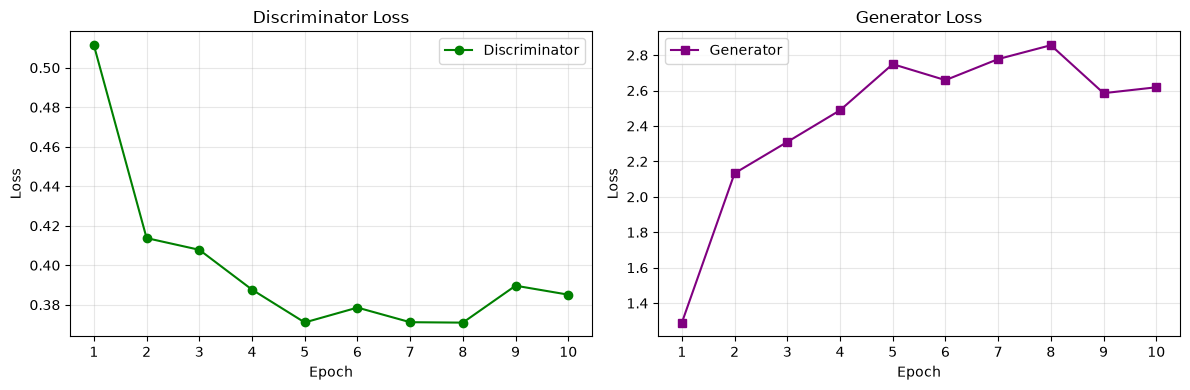

In [14]:
# Plot GAN losses across epochs
epoch_numbers_gan = np.arange(1, epochs_gan + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epoch_numbers_gan, history_gan["discriminator"], marker="o", label="Discriminator", color="green")
axes[0].set_title("Discriminator Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(epoch_numbers_gan)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epoch_numbers_gan, history_gan["generator"], marker="s", label="Generator", color="purple")
axes[1].set_title("Generator Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(epoch_numbers_gan)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()

## 4) GAN – Generation (10 marks)

Use a fixed batch of 64 noise vectors. Save 8×8 grids at epochs 1, 5, and 10.
Comment on progression or mode collapse.

### 4.1) Image Generation from Fixed Noise Samples

A fixed batch of 64 latent noise vectors is sampled from the standard normal distribution and reused throughout training. The generator outputs are saved as \($8\times8$\) grayscale image grids at epochs 1, 5, and 10. Reusing the same latent vectors enables consistent comparisons of sample quality, diversity, and progression across epochs.

In [15]:
# Generate 64 fixed latent noise vectors
sample_generator_gan = torch.Generator(device="cpu").manual_seed(RANDOM_SEED)
fixed_z_gan_64 = torch.randn(64, 64, generator=sample_generator_gan).to(device)

os.makedirs("gan_samples_section4", exist_ok=True)

print(f"Fixed latent vectors shape: {fixed_z_gan_64.shape}")

# Initialize a fresh GAN
generator = Generator().to(device)
discriminator = Discriminator().to(device)

# Define the loss function and optimizers
criterion_gan = nn.BCEWithLogitsLoss()
optimizer_g = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizer_d = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

# Configure GAN training
epochs_gan_section4 = 10
history_gan_section4 = {"discriminator": [], "generator": []}
sample_epochs_gan = [1, 5, 10]

# Train the GAN for 10 epochs
for epoch in range(epochs_gan_section4):
    generator.train()
    discriminator.train()

    epoch_d_loss = 0.0
    epoch_g_loss = 0.0
    sample_count = 0

    for images, _ in train_loader:
        batch_size_actual = images.size(0)

        # Flatten and normalize real images to [-1, 1]
        x_real = images.view(batch_size_actual, -1).to(device)
        x_real = 2 * x_real - 1

        # Create discriminator labels
        real_labels = torch.full((batch_size_actual, 1), 0.9, device=device)
        fake_labels = torch.zeros((batch_size_actual, 1), device=device)

        # Train the discriminator
        optimizer_d.zero_grad()

        real_logits = discriminator(x_real)
        loss_d_real = criterion_gan(real_logits, real_labels)

        z = torch.randn(batch_size_actual, 64, device=device)
        fake_images = generator(z).detach()
        fake_logits = discriminator(fake_images)
        loss_d_fake = criterion_gan(fake_logits, fake_labels)

        loss_d = 0.5 * (loss_d_real + loss_d_fake)
        loss_d.backward()
        optimizer_d.step()

        # Train the generator while freezing discriminator parameters
        optimizer_g.zero_grad()

        for parameter in discriminator.parameters():
            parameter.requires_grad_(False)

        z = torch.randn(batch_size_actual, 64, device=device)
        generated_images = generator(z)
        generated_logits = discriminator(generated_images)
        generator_labels = torch.ones((batch_size_actual, 1), device=device)

        loss_g = criterion_gan(generated_logits, generator_labels)
        loss_g.backward()
        optimizer_g.step()

        for parameter in discriminator.parameters():
            parameter.requires_grad_(True)

        # Accumulate batch-size-weighted losses
        epoch_d_loss += loss_d.item() * batch_size_actual
        epoch_g_loss += loss_g.item() * batch_size_actual
        sample_count += batch_size_actual

    # Calculate average losses for the epoch
    avg_d_loss = epoch_d_loss / sample_count
    avg_g_loss = epoch_g_loss / sample_count

    history_gan_section4["discriminator"].append(avg_d_loss)
    history_gan_section4["generator"].append(avg_g_loss)

    print(
        f"Epoch [{epoch + 1}/{epochs_gan_section4}] "
        f"D Loss: {avg_d_loss:.4f} | G Loss: {avg_g_loss:.4f}"
    )

    # Save fixed-noise samples at epochs 1, 5, and 10
    if epoch + 1 in sample_epochs_gan:
        generator.eval()

        with torch.no_grad():
            generated = generator(fixed_z_gan_64).view(64, 28, 28)
            generated = (generated + 1) / 2

        # Create an 8x8 grid with padding
        fig, axes = plt.subplots(8, 8, figsize=(8, 8))

        for i, ax in enumerate(axes.flat):
            ax.imshow(generated[i].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

        plt.tight_layout(pad=0.1)

        sample_path = f"gan_samples_section4/epoch_{epoch + 1:02d}.png"
        plt.savefig(sample_path, bbox_inches="tight")
        plt.close(fig)

        print(f"Saved GAN sample grid: {sample_path}")
        generator.train()

Fixed latent vectors shape: torch.Size([64, 64])
Epoch [1/10] D Loss: 0.4951 | G Loss: 1.3551
Saved GAN sample grid: gan_samples_section4/epoch_01.png
Epoch [2/10] D Loss: 0.4277 | G Loss: 2.0061
Epoch [3/10] D Loss: 0.4201 | G Loss: 2.2062
Epoch [4/10] D Loss: 0.3955 | G Loss: 2.4001
Epoch [5/10] D Loss: 0.3931 | G Loss: 2.4343
Saved GAN sample grid: gan_samples_section4/epoch_05.png
Epoch [6/10] D Loss: 0.3964 | G Loss: 2.4825
Epoch [7/10] D Loss: 0.3942 | G Loss: 2.5147
Epoch [8/10] D Loss: 0.4006 | G Loss: 2.4032
Epoch [9/10] D Loss: 0.4058 | G Loss: 2.3829
Epoch [10/10] D Loss: 0.4118 | G Loss: 2.3735
Saved GAN sample grid: gan_samples_section4/epoch_10.png


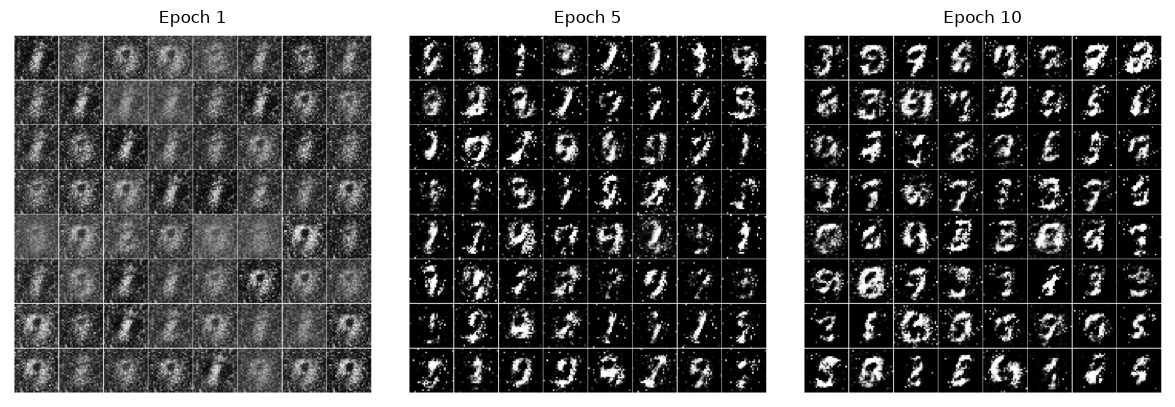

In [16]:
# Display the saved grids from epochs 1, 5, and 10
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, epoch in enumerate(sample_epochs_gan):
    sample_path = f"gan_samples_section4/epoch_{epoch:02d}.png"
    grid = plt.imread(sample_path)

    axes[i].imshow(grid, cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(f"Epoch {epoch}")
    axes[i].axis("off")

plt.tight_layout()

### 4.2) Comment on Progression and Mode Collapse

- **Progression:** Generated images improve from noisy patterns at Epoch 1 to recognizable digit shapes by Epoch 10.
- **Image quality:** The digits remain noisy and some are poorly defined, indicating scope for further training.
- **Diversity:** Multiple digit classes and variations are visible across the samples.
- **Mode collapse:** No severe mode collapse is apparent, as different digit patterns are preserved across samples, although repetition of a few digits suggests that partial mode collapse may be possible.

## 5) Quantitative Comparison (20 marks)

Compute Inception Score (IS) and Fréchet Distance (FID) for 100 generated samples for both VAE and GAN using a fixed MNIST classifier you train:

- **Classifier (for IS/FID features):**
    - Conv2d(1→32, k=3, s=1, p=1) → ReLU → MaxPool(2);
    - Conv2d(32→64, k=3, s=1, p=1) → ReLU → MaxPool(2);
    - Flatten → Linear(\($7 \cdot 7 \cdot 64 \to 128$\)) → ReLU → Linear(\($128 \to 10$\)) → Softmax.
    - Train 5 epochs on MNIST train (60k), Adam(lr=1e-3), batch=128; freeze afterward.

- **IS:** Split 100 samples into 10 splits; 
  \($\mathrm{IS} = \exp\left(\mathbb{E}\left[D_{\mathrm{KL}}(p(y\mid x)\,\|\,p(y))\right]\right)$\); report mean ± std across splits.

- **FID:** Use 128-dim penultimate activations as features. Compute \(($\mu_r,\Sigma_r$)\) on 1,000 real test
  images and \(($\mu_g,\Sigma_g$)\) on 100 generated; 
  \($\mathrm{FID} = \|\mu_r - \mu_g\|_2^2 + \operatorname{Tr}\left(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\right)$\).

- **Output:** Table with IS (higher is better) and FID (lower is better) for VAE vs GAN.

### 5.1) MNIST Classifier Architecture

A CNN classifier is defined according to the specified architecture. Two convolutional layers, each followed by ReLU activation and max pooling, are used to extract spatial features from the input images. The resulting feature maps are flattened and passed through a fully connected layer containing 128 neurons, followed by a 10-class output layer. The 128-dimensional activations are exposed separately for FID computation, while logits are returned for classification.

In [17]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(7 * 7 * 64, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 28x28 -> 14x14
        x = self.pool(F.relu(self.conv2(x)))  # 14x14 -> 7x7
        x = x.view(x.size(0), -1)
        features = F.relu(self.fc1(x))
        logits = self.fc2(features)
        return logits

    def extract_features(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        return F.relu(self.fc1(x))

classifier = MNISTClassifier().to(device)
criterion_classifier = nn.CrossEntropyLoss()
optimizer_classifier = optim.Adam(classifier.parameters(), lr=1e-3)

### 5.2) Classifier Training and Evaluation

The classifier is trained for 5 epochs using the `Adam` optimizer with a learning rate of $10^{-3}$ and cross-entropy loss. Classification accuracy and average training loss are calculated and reported after each epoch. The trained classifier is subsequently evaluated on the MNIST test set, and its test accuracy is reported. After training, the classifier parameters are frozen and the model is placed in evaluation mode so that its learned representations can be used consistently during metric computation.

In [18]:
epochs_classifier = 5

for epoch in range(epochs_classifier):
    classifier.train()
    total_loss = 0.0
    correct = 0
    sample_count = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_classifier.zero_grad()
        logits = classifier(images)
        loss = criterion_classifier(logits, labels)
        loss.backward()
        optimizer_classifier.step()

        batch_size_actual = images.size(0)
        total_loss += loss.item() * batch_size_actual
        correct += (logits.argmax(dim=1) == labels).sum().item()
        sample_count += batch_size_actual

    print(
        f"Epoch [{epoch + 1}/{epochs_classifier}] "
        f"Loss: {total_loss / sample_count:.4f} | "
        f"Accuracy: {100 * correct / sample_count:.2f}%"
    )

# Evaluate classifier on the MNIST test set
classifier.eval()
correct = 0
sample_count = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        predictions = classifier(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        sample_count += labels.size(0)

print(f"Classifier test accuracy: {100 * correct / sample_count:.2f}%")

# Freeze the trained classifier
for parameter in classifier.parameters():
    parameter.requires_grad_(False)

classifier.eval()

Epoch [1/5] Loss: 0.2541 | Accuracy: 92.30%
Epoch [2/5] Loss: 0.0616 | Accuracy: 98.10%
Epoch [3/5] Loss: 0.0431 | Accuracy: 98.65%
Epoch [4/5] Loss: 0.0345 | Accuracy: 98.88%
Epoch [5/5] Loss: 0.0250 | Accuracy: 99.19%
Classifier test accuracy: 98.84%


MNISTClassifier(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

### 5.3) Generation of 100 Samples

One hundred images are generated independently from each trained generative model. For the VAE, 100 latent vectors of dimension 16 are sampled from a standard normal distribution and decoded into images. For the GAN, 100 latent vectors of dimension 64 are sampled and passed through the trained generator. Since the GAN generator produces values in ([-1,1]), its outputs are rescaled to ([0,1]).

In [19]:
# Generate 100 samples from the VAE
sample_generator_vae = torch.Generator(device="cpu").manual_seed(RANDOM_SEED)
z_vae = torch.randn(100, 16, generator=sample_generator_vae).to(device)

vae.eval()
with torch.no_grad():
    generated_vae = vae.decode(z_vae).view(100, 1, 28, 28)
    generated_vae = generated_vae.clamp(0, 1)

# Generate 100 samples from the GAN
sample_generator_gan = torch.Generator(device="cpu").manual_seed(RANDOM_SEED)
z_gan = torch.randn(100, 64, generator=sample_generator_gan).to(device)

generator.eval()
with torch.no_grad():
    generated_gan = generator(z_gan).view(100, 1, 28, 28)
    generated_gan = ((generated_gan + 1) / 2).clamp(0, 1)

print(f"VAE generated samples: {generated_vae.shape}")
print(f"GAN generated samples: {generated_gan.shape}")

VAE generated samples: torch.Size([100, 1, 28, 28])
GAN generated samples: torch.Size([100, 1, 28, 28])


### 5.4) Inception Score (IS)

The Inception Score is computed using the trained MNIST classifier. Class probabilities are obtained by applying softmax to the classifier logits for the generated images. The 100 samples are divided into 10 splits, with 10 images in each split. For every split, the marginal class distribution is estimated, and the `Kullback–Leibler divergence` between each image's conditional class distribution and the marginal distribution is calculated. The mean divergence is exponentiated to obtain the split-wise IS. Finally, the mean and standard deviation of the 10 split scores are reported for both the VAE and GAN. A higher IS is generally preferred.

In [20]:
def calculate_inception_score(images, classifier, n_splits=10):
    classifier.eval()

    with torch.no_grad():
        logits = classifier(images.to(device))
        probabilities = F.softmax(logits, dim=1).cpu().numpy()

    split_scores = []

    for split in np.array_split(probabilities, n_splits):
        marginal_prob = np.mean(split, axis=0)
        kl_values = split * (np.log(np.clip(split, 1e-12, None)) - np.log(np.clip(marginal_prob, 1e-12, None)))
        kl_per_image = np.sum(kl_values, axis=1)
        split_score = np.exp(np.mean(kl_per_image))
        split_scores.append(split_score)

    return np.mean(split_scores), np.std(split_scores)

is_vae_mean, is_vae_std = calculate_inception_score(generated_vae, classifier)
is_gan_mean, is_gan_std = calculate_inception_score(generated_gan, classifier)

print(f"VAE IS: {is_vae_mean:.4f} ± {is_vae_std:.4f}")
print(f"GAN IS: {is_gan_mean:.4f} ± {is_gan_std:.4f}")

VAE IS: 4.3223 ± 0.6317
GAN IS: 3.0912 ± 0.6716


### 5.5) Fréchet Distance (FID)

The 128-dimensional penultimate activations of the trained classifier are extracted for 1,000 real MNIST test images and 100 generated images from each model. The corresponding feature means and covariance matrices are computed. FID is then calculated using the squared distance between the feature means and the trace-based covariance distance, which includes the matrix square root of the product of the covariance matrices. A small diagonal regularization term is added to the covariance matrices to improve numerical stability. Lower FID values indicate greater similarity between the generated and real feature distributions.

In [21]:
from scipy.linalg import sqrtm

def extract_classifier_features(images, classifier, batch_size=128):
    classifier.eval()
    feature_batches = []

    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size].to(device)
            features = classifier.extract_features(batch)
            feature_batches.append(features.cpu().numpy())

    return np.concatenate(feature_batches, axis=0)

def calculate_fid(real_features, generated_features):
    mu_real = np.mean(real_features, axis=0)
    mu_generated = np.mean(generated_features, axis=0)

    sigma_real = np.cov(real_features, rowvar=False)
    sigma_generated = np.cov(generated_features, rowvar=False)

    # Add a small diagonal term for numerical stability
    epsilon = 1e-6
    sigma_real += epsilon * np.eye(sigma_real.shape[0])
    sigma_generated += epsilon * np.eye(sigma_generated.shape[0])

    mean_difference = mu_real - mu_generated
    covariance_product_sqrt = sqrtm(sigma_real @ sigma_generated)
    
    if not np.isfinite(covariance_product_sqrt).all():
        raise ValueError("FID covariance square root contains non-finite values.")

    if np.iscomplexobj(covariance_product_sqrt):
        covariance_product_sqrt = covariance_product_sqrt.real

    fid = (mean_difference @ mean_difference + np.trace(sigma_real + sigma_generated - 2 * covariance_product_sqrt))
    
    return float(max(fid, 0.0))

# Collect 1,000 real MNIST test images
real_images_list = []
real_count = 0

for images, _ in test_loader:
    needed = min(images.size(0), 1000 - real_count)
    real_images_list.append(images[:needed])
    real_count += needed

    if real_count >= 1000:
        break

real_images = torch.cat(real_images_list, dim=0)

# Extract 128-dimensional features
real_features = extract_classifier_features(real_images, classifier)
vae_features = extract_classifier_features(generated_vae, classifier)
gan_features = extract_classifier_features(generated_gan, classifier)

# Calculate FID
fid_vae = calculate_fid(real_features, vae_features)
fid_gan = calculate_fid(real_features, gan_features)

print(f"VAE FID: {fid_vae:.4f}")
print(f"GAN FID: {fid_gan:.4f}")

VAE FID: 250.0086
GAN FID: 425.9300


### 5.6) Quantitative Comparison

The IS mean and standard deviation and the FID value are presented in a comparison table for the VAE and GAN. 

In [22]:
# Display the IS and FID comparison table
print("\nQuantitative Comparison")
print("-" * 50)
print(f"{'Model':<10}{'IS (mean ± std)':<20}{'FID':>10}")
print("-" * 50)
print(f"{'VAE':<10}{is_vae_mean:.4f} ± {is_vae_std:.4f}"
      f"{fid_vae:>16.4f}")
print(f"{'GAN':<10}{is_gan_mean:.4f} ± {is_gan_std:.4f}"
      f"{fid_gan:>16.4f}")
print("-" * 50)


Quantitative Comparison
--------------------------------------------------
Model     IS (mean ± std)            FID
--------------------------------------------------
VAE       4.3223 ± 0.6317        250.0086
GAN       3.0912 ± 0.6716        425.9300
--------------------------------------------------


**Observation:** The VAE outperforms the GAN on both metrics, achieving a higher IS and a lower FID. This suggests more distinguishable digit classes and greater similarity to the real data distribution in the chosen classifier's feature space.

**Reason:** The VAE's latent-space regularization encourages structured representations and may support better coverage of digit variations. In contrast, unstable generator–discriminator training may hinder GAN convergence, while partial mode collapse may limit the diversity of generated samples. These factors could explain the observed performance difference.

---
End of the assignment